In [179]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
path = str(Path(Path('File.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

path = str(Path(Path('thermo.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

import numpy as np
import matplotlib as mlab
import matplotlib.pyplot as plt
import scipy
import xarray as xr
import os as os
import glob
import matplotlib.gridspec as gridspec
import tools
from tools.cbook import pickle2Obj, interp_z, compute_thetae
from tools.FV3_tools import read_solo_fields
from tools.CM1_tools import read_cm1_fields
import matplotlib.transforms as transforms

from pltbook import nice_clevels, nice_mxmnintvl, container, plot_contour_row

import matplotlib.colors as mcolors

cmap_data = [(1.0, 1.0, 1.0),
         (0.3137255012989044, 0.8156862854957581, 0.8156862854957581),
         (0.0, 1.0, 1.0),
         (0.0, 0.8784313797950745, 0.501960813999176),
         (0.0, 0.7529411911964417, 0.0),
         (0.501960813999176, 0.8784313797950745, 0.0),
         (1.0, 1.0, 0.0),
         (1.0, 0.6274510025978088, 0.0),
         (1.0, 0.0, 0.0),
         (1.0, 0.125490203499794, 0.501960813999176),
         (0.9411764740943909, 0.250980406999588, 1.0),
         (0.501960813999176, 0.125490203499794, 1.0),
         (0.250980406999588, 0.250980406999588, 1.0),
         (0.125490203499794, 0.125490203499794, 0.501960813999176),
         (0.125490203499794, 0.125490203499794, 0.125490203499794),
         (0.501960813999176, 0.501960813999176, 0.501960813999176),
         (0.8784313797950745, 0.8784313797950745, 0.8784313797950745),
         (0.9333333373069763, 0.8313725590705872, 0.7372549176216125),
         (0.8549019694328308, 0.6509804129600525, 0.47058823704719543),
         (0.6274510025978088, 0.42352941632270813, 0.23529411852359772),
         (0.4000000059604645, 0.20000000298023224, 0.0)]

# draw filled contours.
wclevs = [0, 1, 2.5, 5, 7.5, 10, 15, 20, 30, 40, 50, 60, 70]

tclevs = list(-40.0 + 2*np.arange(41))

teclevs = list(300. + 5*np.arange(70))

bclevs = list(-0.4+ 0.02*np.arange(100))
pclevs = list(-15.0 + np.arange(31))

dclevs = list(-20.0 + np.arange(41))

zlevels = 10.0 + 100.*np.arange(200)

def label_panels(axs, panel_labels, fontsize=14, adjust_loc=None):

    from operator import add

    base_loc = [0.025, 0.975]

    if adjust_loc:
        loc = list(map(add, base_loc, adjust_loc)) 
    else:
        loc = base_loc

    for i, ax in enumerate(axs.flatten()):
    # Add the panel label
        ax.text(*loc, panel_labels[i], transform=ax.transAxes, fontsize=fontsize, fontweight='medium', va='top', ha='left')

    return axs

def find_max_ijk(array):
    
    flat_max_index = np.argmax( array )
    return np.unravel_index(flat_max_index, array.shape)

linestyles = ['solid','--',':'] 

#=============================================================================
paths = {}
paths['cm1']     = '/work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14'
#paths['cm1_w0']  = '/work/wicker/climate_runs/cm1r20.3/run/bubble_WW0/3km/QV14'
paths['solo']    = '/work/wicker/climate_runs/FV3_Solo/bubble/euler/3km/QV14'

models = {}
for key in paths:
    print("\n Reading: ",key)
    if key[0:3] == 'cm1':
        models[key] = ( read_cm1_fields(paths[key], vars = ['w', 'pert_p',  'buoy', 'qc'], ret_pb=True, zinterp=zlevels, ret_ds=False) )
    if key[0:4] == 'solo':
        models[key] = ( read_solo_fields(paths[key], vars = ['w', 'pert_p', 'buoy', 'qc'], ret_pb=True, zinterp=zlevels, ret_ds=False) )

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload

 Reading:  cm1
------------------------------------------------------------------------------------------------------------------------

 Now reading... /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc

 Time for xarray to load:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc: 0.14 sec 

 Completed setup for:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc --> time to initialize variables: 0.67 sec 

 336.3203 -2923.421

 Reading Pb from /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/pb.nc

 Completed reading in:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc --> time to process variables: 1.47 sec 

 Interpolating fields to single column z-grid: /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14/cm1out.nc 

 Interpolated completed, Total CPU:  /work/wicker/climate_runs/cm1r20.3/run/bubble/3km/QV14: 1.40 sec 

 Total

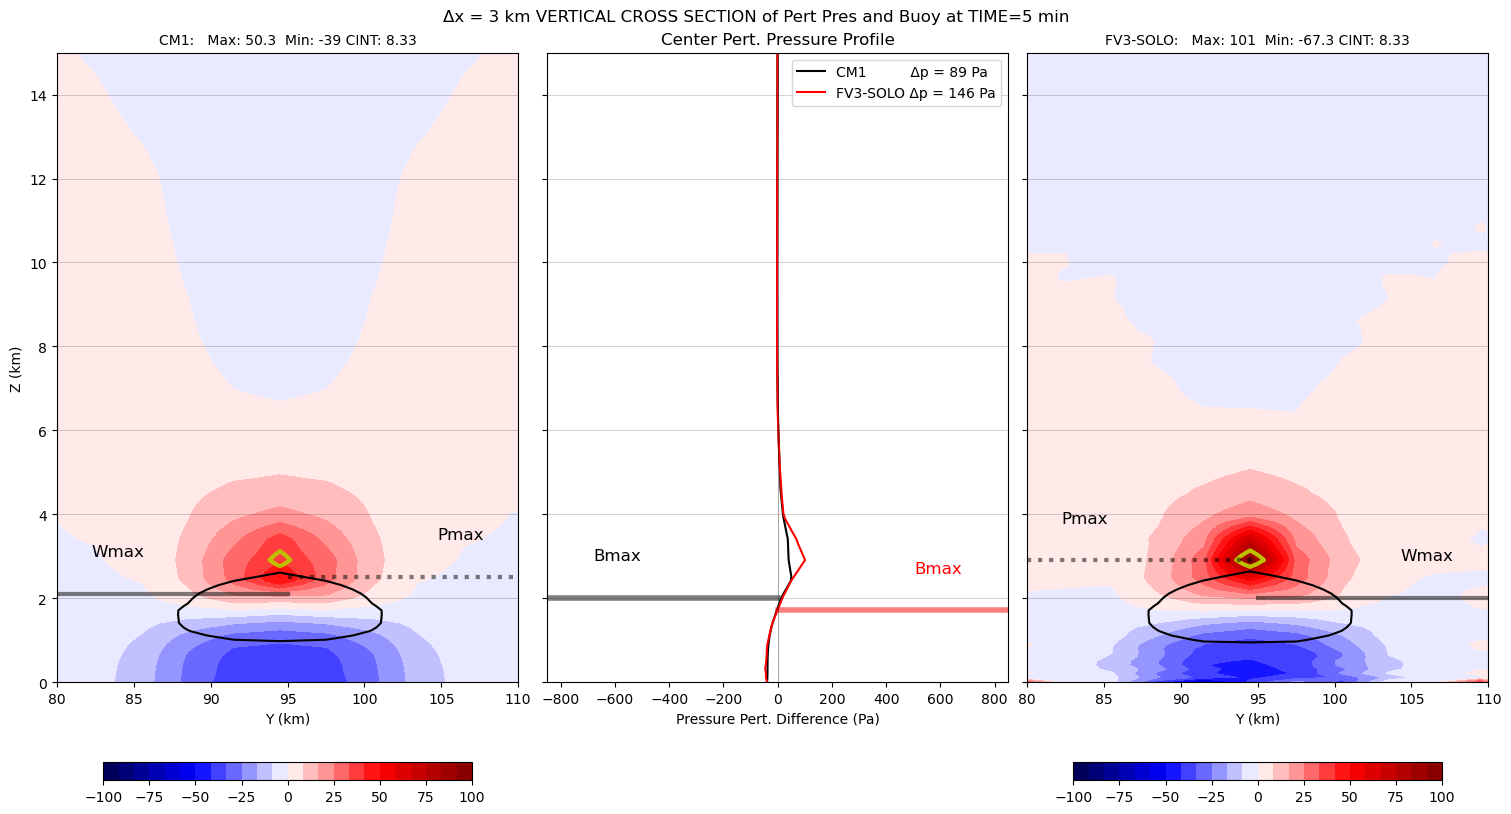

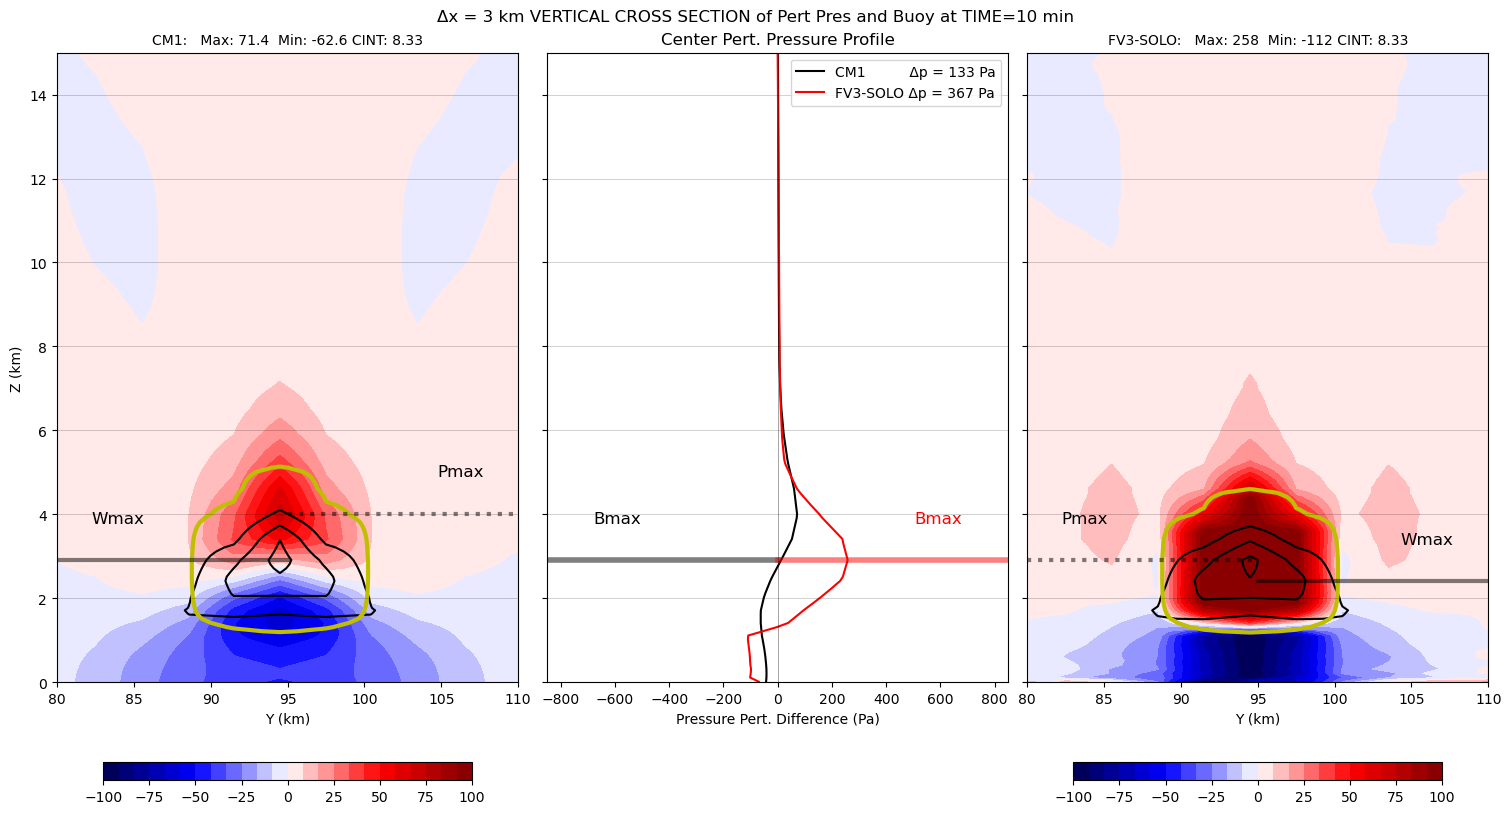

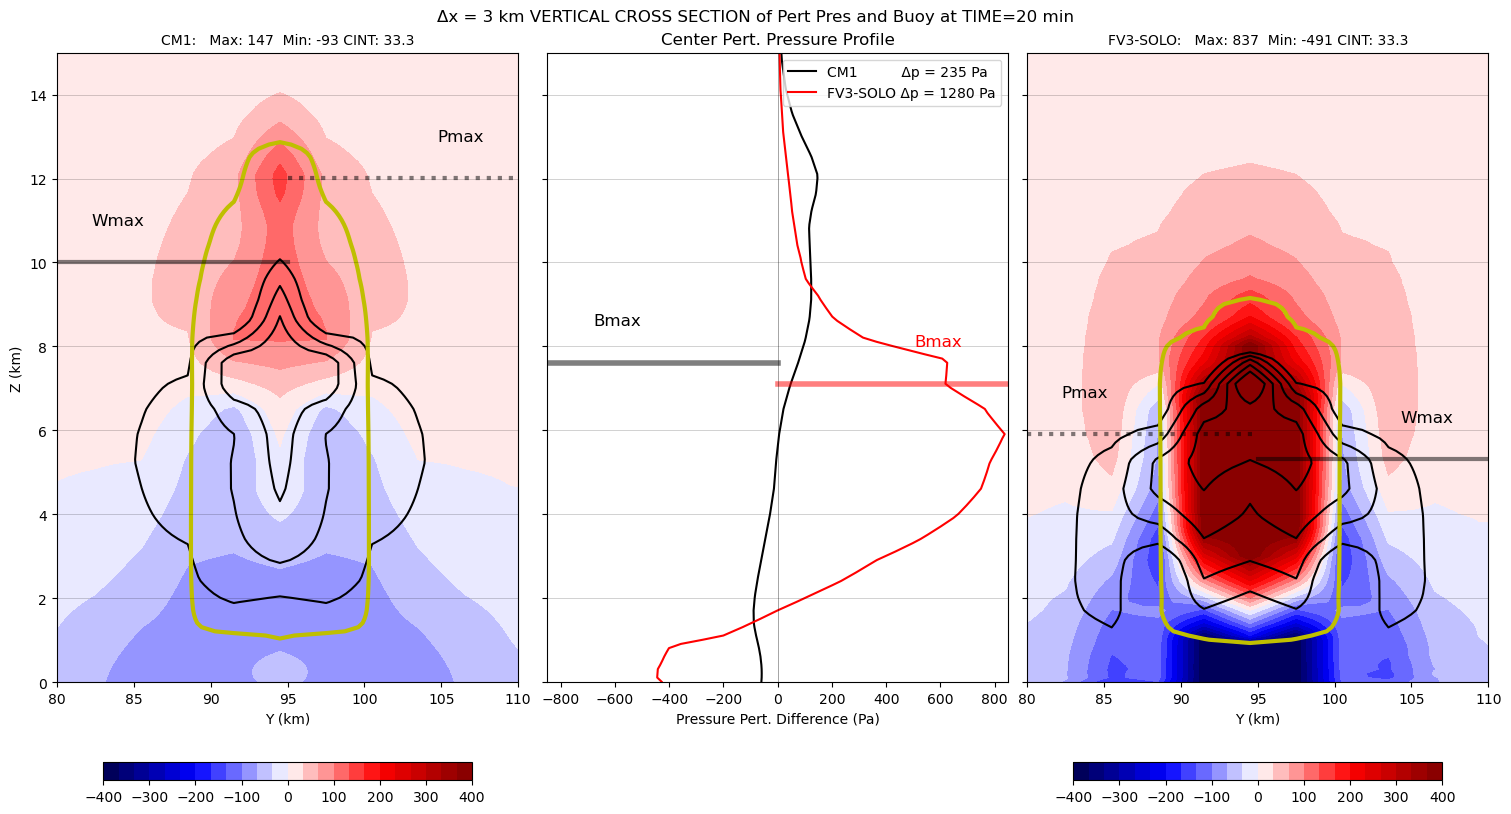

In [180]:
solo = models['solo']
cm1  = models['cm1']

time1 = solo['min'][:]
time2 = cm1['min'][:]
xc    = cm1['xc']/1000.
yc    = cm1['yc']/1000.

nx2 = (xc.shape[0]//2) - 1
ny2 = (yc.shape[0]//2) - 1

dp_unicode = "\u0394p"
linestyles = [':','--','solid'] 

for tlevel in [5, 10, 20]:

    match tlevel:
        case 1:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 5:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 10:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 15:
            pclevs  = list(np.linspace(-200,200,25))
            pclevs2 = [x*2 for x in pclevs]
        case 20:
            pclevs  = list(np.linspace(-400,400,25))
            pclevs2 = [x*1 for x in pclevs]
        case _:
            pclevs  = list(np.linspace(-400,400,25))
            pclevs2 = [x*1 for x in pclevs]

    pfield = 'pert_p2'

    ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,8))

    pdiff_cm1 = int(cm1['pert_p'][tlevel, :,nx2,ny2].max() - cm1['pert_p'][tlevel, :,nx2,ny2].min())
    pdiff_sol = int(solo[pfield][tlevel-1, :,nx2,ny2].max() - solo[pfield][tlevel-1, :,nx2,ny2].min())

    axes[1].plot(cm1['pert_p'][tlevel, :,nx2,ny2], zlevels/1000., color='k', linestyle=linestyles[2],     label=f'CM1          {dp_unicode} = {pdiff_cm1} Pa')
    axes[1].plot(solo[pfield][tlevel-1,:,nx2,ny2], zlevels/1000., color='r', linestyle=linestyles[2],   label=f'FV3-SOLO {dp_unicode} = {pdiff_sol} Pa')
    axes[1].legend(loc='upper right', fontsize=10)
    axes[1].set_title(f"Center Pert. Pressure Profile")
    axes[1].set_xlim(-850,850)

    fields = []
    fields.append(container( cm1['pert_p'][tlevel,  :,:,ny2], yc, zlevels/1000.,   cint=pclevs, cmap=plt.cm.seismic))
    # fields.append(container( cm1_w0['pert_p'][tlevel,  :,:,ny2], yc, zlevels/1000.,   cint=pclevs, cmap=plt.cm.seismic))
    fields.append(container(solo[pfield][tlevel-1,:,:,ny2], yc, zlevels/1000.,   cint=pclevs2, cmap=plt.cm.seismic)) 

    plot_contour_row(fields, plot_type=2, ptitle=['CM1', 'FV3-SOLO'], suptitle=f"\u0394x = 3 km VERTICAL CROSS SECTION of Pert Pres and Buoy at TIME={tlevel} min", 
                                 xlabel='X (km)', ylabel='Z (km)', xlim=[80.,110.], ax_in=[axes[0],axes[2]]);
    
    bclevs  = list(np.linspace(0.025,0.225,5))
    axes[0].contour(yc, zlevels/1000., cm1['buoy'][tlevel,  :,:,ny2], levels=bclevs,  colors=['k',], linewidth=[0.25,] )
    axes[2].contour(yc, zlevels/1000., solo['buoy'][tlevel-1,:,:,ny2], levels=bclevs, colors=['k',], linewidth=[0.25,] )
    axes[0].set_xlim(80.,110.)
    axes[2].set_xlim(80.,110.)
    axes[0].set_xlabel('Y (km)')
    axes[2].set_xlabel('Y (km)')
    axes[1].set_xlabel('Pressure Pert. Difference (Pa)')

    ckmax, _, _ = find_max_ijk(cm1['buoy'][tlevel])
    skmax, _, _ = find_max_ijk(solo['buoy'][tlevel-1])
    axes[1].axhline(y = zlevels[ckmax]/1000., xmin=0., xmax=0.5, color = 'k', alpha=0.5, linewidth=4.0 )
    axes[1].axhline(y = zlevels[skmax]/1000., xmin=0.5, xmax=1.0, color = 'r', alpha=0.5, linewidth=4.0 ) 
    axes[1].axvline(x = 0.0, color = 'k', alpha=0.5, linewidth=0.50 )
        # Add text info
    trans = transforms.blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.1, 1 + zlevels[ckmax]/1000., "Bmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='left')
    axes[1].text(0.9, 1 + zlevels[skmax]/1000., "Bmax", transform=trans, fontsize=12, color='r', verticalalignment='center', horizontalalignment='right')

    # Plot qc contours
    cclevs  = [0.1,]
    axes[0].contour(yc, zlevels/1000., cm1['qc'][tlevel,  :,:,ny2]*1000, levels=cclevs,  colors=['y',], linewidths=[3.0,] )
    axes[2].contour(yc, zlevels/1000., solo['qc'][tlevel-1,:,:,ny2]*1000., levels=cclevs, colors=['y',], linewidths=[3.0,] )
    axes[0].set_xlim(80.,110.)
    axes[2].set_xlim(80.,110.)

    axes[0].set_ylim(0.,15.)
    axes[2].set_ylim(0.,15.)

    # max p label
    ckmax, _, _ = find_max_ijk(cm1['pert_p'][tlevel])
    skmax, _, _ = find_max_ijk(solo[pfield][tlevel-1])
    axes[0].axhline(y = zlevels[ckmax]/1000., xmin=0.5, xmax=1.0, color = 'k', alpha=0.5, linestyle=linestyles[0], linewidth=3.0 )
    axes[2].axhline(y = zlevels[skmax]/1000., xmin=0.0, xmax=0.5, color = 'k', alpha=0.5, linestyle=linestyles[0], linewidth=3.0 )
    trans = transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
    axes[0].text(0.925, 1 + zlevels[ckmax]/1000., "Pmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='right')
    trans = transforms.blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.075, 1 + zlevels[skmax]/1000., "Pmax", transform=trans, fontsize=12, color='k', verticalalignment='center', horizontalalignment='left')

    # max w label
    ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])
    axes[0].axhline(y = zlevels[ckmax]/1000., xmin=0., xmax=0.5, color = 'k', alpha=0.5, linestyle=linestyles[2], linewidth=3.0 )
    axes[2].axhline(y = zlevels[skmax]/1000., xmin=0.5, xmax=1.0, color = 'k', alpha=0.5, linestyle=linestyles[2], linewidth=3.0 )
    trans = transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
    axes[0].text(0.075, 1 + zlevels[ckmax]/1000., "Wmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='left')
    trans = transforms.blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.925, 1 + zlevels[skmax]/1000., "Wmax", transform=trans, fontsize=12, color='k', verticalalignment='center', horizontalalignment='right')

    # other lines of interest
    for hgt in [2., 4., 6.0, 8.0, 10., 12., 14.0]:
        axes[0].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
        axes[1].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
        axes[2].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
    
    axes[0].set_ylabel('Z (km)', fontsize=10);
    # label_panels(axes, ['(a)', '(b)', '(c)'], fontsize=18)

    plt.savefig("../Figures/Figure13_XZ_PertP_Buoy_3km_PertP_TIME_%2.2d_min.pdf" % tlevel)

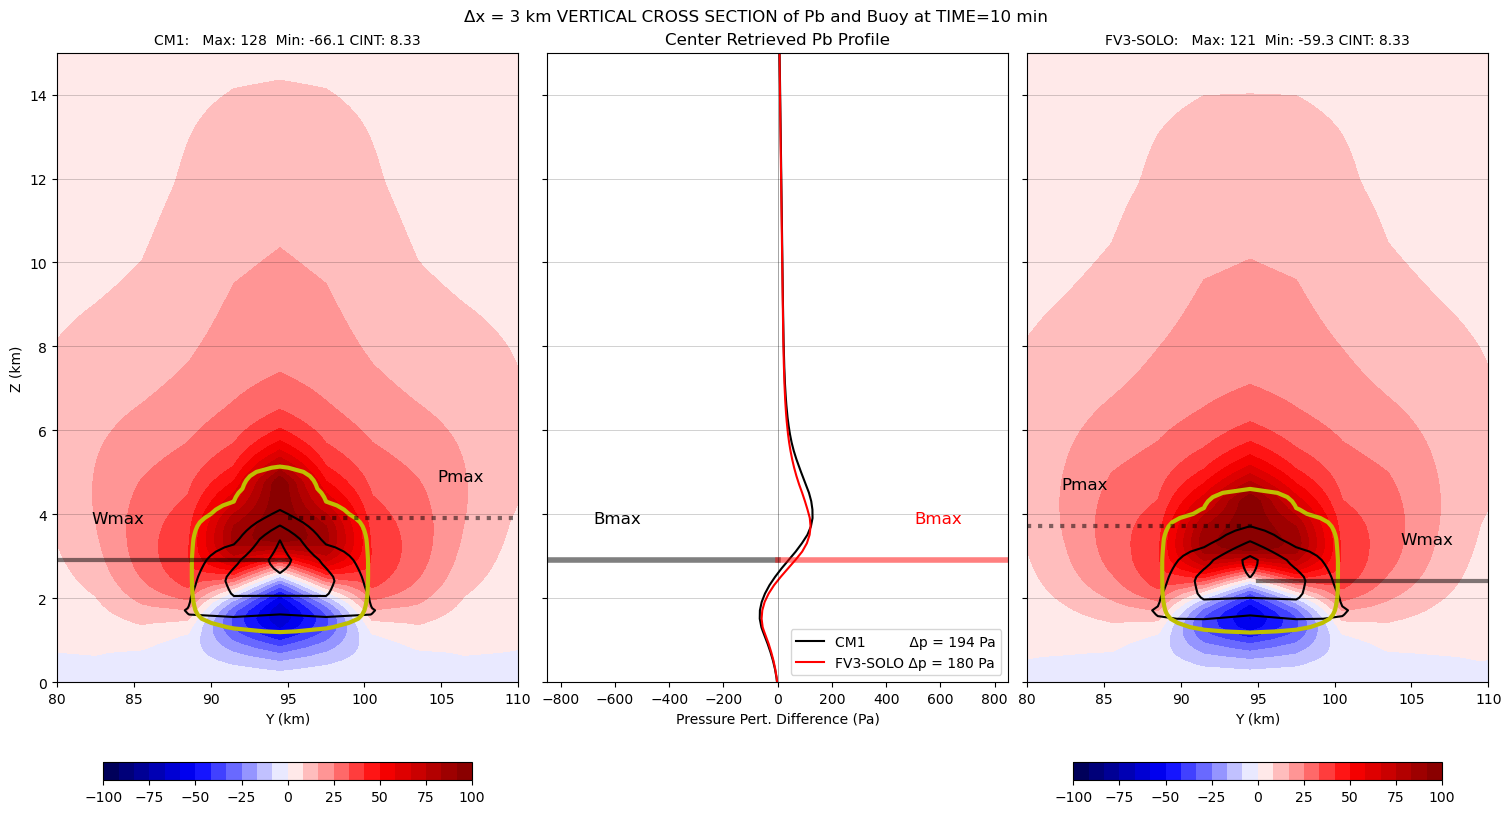

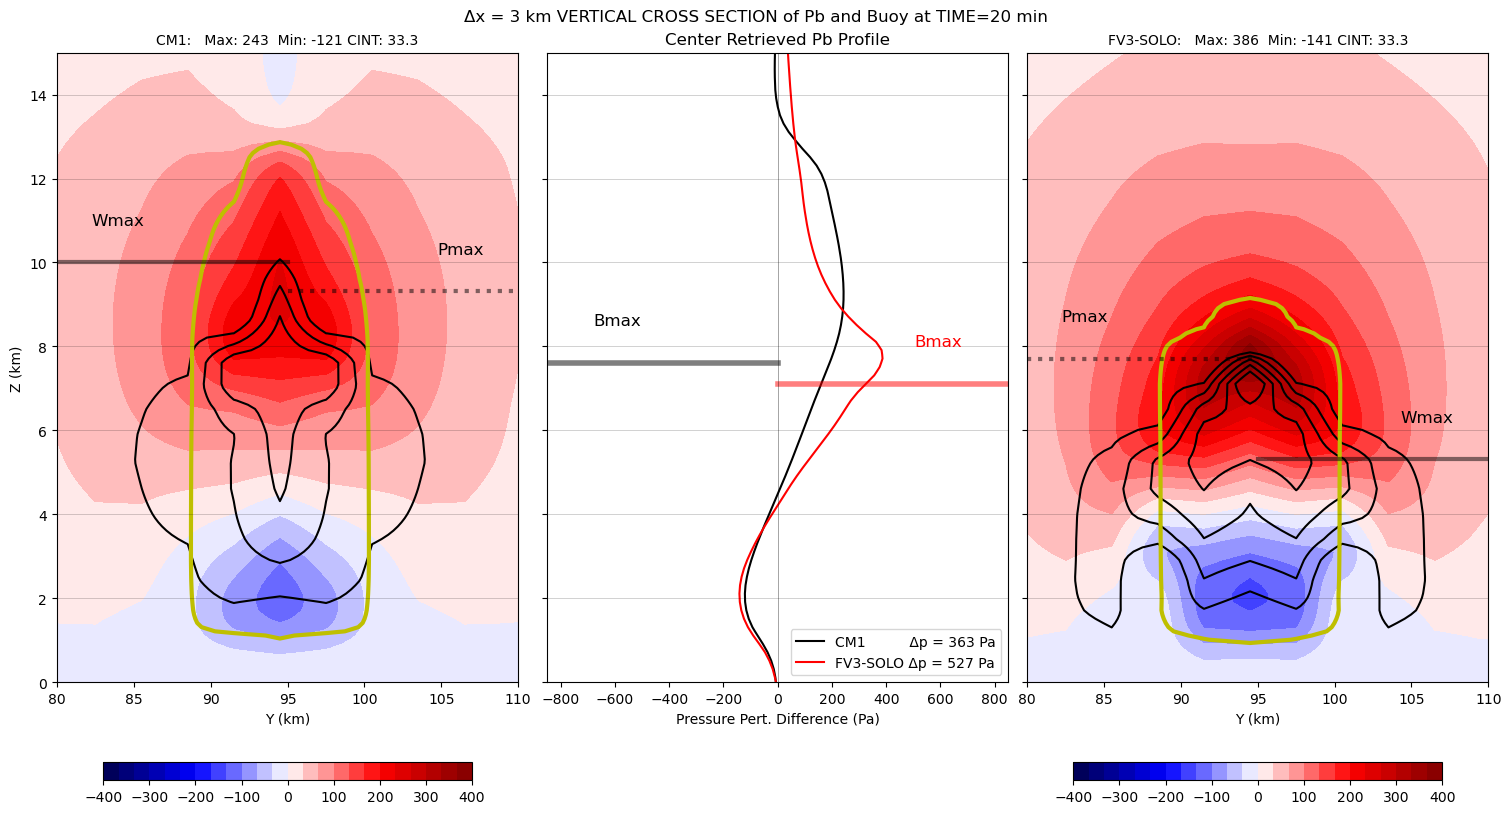

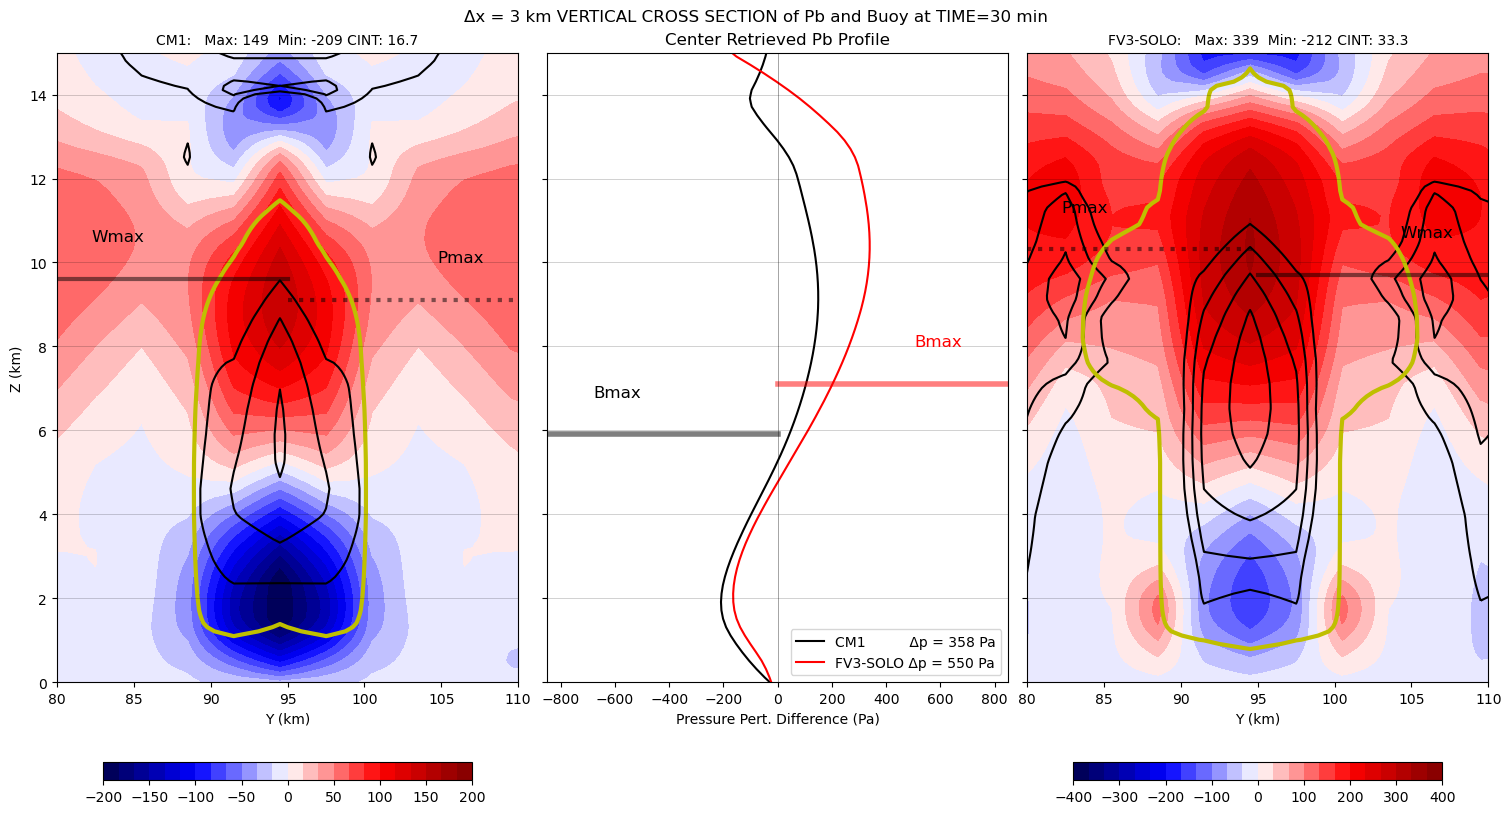

In [184]:
solo = models['solo']
cm1  = models['cm1']

time1 = solo['min'][:]
time2 = cm1['min'][:]
xc    = cm1['xc']/1000.
yc    = cm1['yc']/1000.

nx2 = (xc.shape[0]//2) - 1
ny2 = (yc.shape[0]//2) - 1

dp_unicode = "\u0394p"
linestyles = [':','--','solid'] 

for tlevel in [10, 20, 30]:

    match tlevel:
        case 1:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 5:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 10:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 15:
            pclevs  = list(np.linspace(-400,400,25))
            pclevs2 = [x*1 for x in pclevs]
        case 20:
            pclevs  = list(np.linspace(-400,400,25))
            pclevs2 = [x*1 for x in pclevs]
        case 30:
            pclevs  = list(np.linspace(-200,200,25))
            pclevs2 = [x*2 for x in pclevs]

    ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,8))

    pdiff_cm1 = int(cm1['pb'][tlevel, :,nx2,ny2].max() - cm1['pb'][tlevel, :,nx2,ny2].min())
    pdiff_sol = int(solo['pb'][tlevel-1, :,nx2,ny2].max() - solo['pb'][tlevel-1, :,nx2,ny2].min())

    axes[1].plot(cm1['pb'][tlevel, :,nx2,ny2], zlevels/1000., color='k', linestyle=linestyles[2],     label=f'CM1          {dp_unicode} = {pdiff_cm1} Pa')
    axes[1].plot(solo['pb'][tlevel-1,:,nx2,ny2], zlevels/1000., color='r', linestyle=linestyles[2],   label=f'FV3-SOLO {dp_unicode} = {pdiff_sol} Pa')
    axes[1].legend()
    axes[1].set_title(f"Center Retrieved Pb Profile")
    axes[1].set_xlim(-850,850)

    fields = []
    fields.append(container( cm1['pb'][tlevel,  :,:,ny2], yc, zlevels/1000.,   cint=pclevs, cmap=plt.cm.seismic))
    # fields.append(container( cm1_w0['pert_p'][tlevel,  :,:,ny2], yc, zlevels/1000.,   cint=pclevs, cmap=plt.cm.seismic))
    fields.append(container(solo['pb'][tlevel-1,:,:,ny2], yc, zlevels/1000.,   cint=pclevs2, cmap=plt.cm.seismic)) 

    plot_contour_row(fields, plot_type=2, ptitle=['CM1', 'FV3-SOLO'], suptitle=f"\u0394x = 3 km VERTICAL CROSS SECTION of Pb and Buoy at TIME={tlevel} min", 
                                 xlabel='X (km)', ylabel='Z (km)', xlim=[80.,112.], ax_in=[axes[0],axes[2]]);
    
    bclevs  = list(np.linspace(0.025,0.225,5))
    #print(bclevs)
    axes[0].contour(yc, zlevels/1000., cm1['buoy'][tlevel,  :,:,ny2], levels=bclevs,  colors=['k',], linewidth=[0.5,] )
    axes[2].contour(yc, zlevels/1000., solo['buoy'][tlevel-1,:,:,ny2], levels=bclevs, colors=['k',], linewidth=[0.5,] )
    axes[0].set_xlim(80.,110.)
    axes[2].set_xlim(80.,110.)
    axes[0].set_xlabel('Y (km)')
    axes[2].set_xlabel('Y (km)')
    axes[1].set_xlabel('Pressure Pert. Difference (Pa)')

    ckmax, _, _ = find_max_ijk(cm1['buoy'][tlevel])
    skmax, _, _ = find_max_ijk(solo['buoy'][tlevel-1])
    axes[1].axhline(y = zlevels[ckmax]/1000., xmin=0., xmax=0.5, color = 'k', alpha=0.5, linewidth=4.0 )
    axes[1].axhline(y = zlevels[skmax]/1000., xmin=0.5, xmax=1.0, color = 'r', alpha=0.5, linewidth=4.0 ) 
    axes[1].axvline(x = 0.0, color = 'k', alpha=0.5, linewidth=0.50 )
    # Add text info
    trans = transforms.blended_transform_factory(axes[1].transAxes, axes[1].transData)
    axes[1].text(0.1, 1 + zlevels[ckmax]/1000., "Bmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='left')
    axes[1].text(0.9, 1 + zlevels[skmax]/1000., "Bmax", transform=trans, fontsize=12, color='r', verticalalignment='center', horizontalalignment='right')

    # Plot qc contours
    cclevs  = [0.1,]
    axes[0].contour(yc, zlevels/1000., cm1['qc'][tlevel,  :,:,ny2]*1000, levels=cclevs,  colors=['y',], linewidths=[3.0,] )
    axes[2].contour(yc, zlevels/1000., solo['qc'][tlevel-1,:,:,ny2]*1000., levels=cclevs, colors=['y',], linewidths=[3.0,] )
    axes[0].set_xlim(80.,110.)
    axes[2].set_xlim(80.,110.)

    axes[0].set_ylim(0.,15.)
    axes[2].set_ylim(0.,15.)
    
    # max p label
    ckmax, _, _ = find_max_ijk(cm1['pb'][tlevel])
    skmax, _, _ = find_max_ijk(solo['pb'][tlevel-1])
    axes[0].axhline(y = zlevels[ckmax]/1000., xmin=0.5, xmax=1.0, color = 'k', alpha=0.5, linestyle=linestyles[0], linewidth=3.0 )
    axes[2].axhline(y = zlevels[skmax]/1000., xmin=0.0, xmax=0.5, color = 'k', alpha=0.5, linestyle=linestyles[0], linewidth=3.0 )
    trans = transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
    axes[0].text(0.925, 1 + zlevels[ckmax]/1000., "Pmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='right')
    trans = transforms.blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.075, 1 + zlevels[skmax]/1000., "Pmax", transform=trans, fontsize=12, color='k', verticalalignment='center', horizontalalignment='left')

    # max w label
    ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])
    axes[0].axhline(y = zlevels[ckmax]/1000., xmin=0., xmax=0.5, color = 'k', alpha=0.5, linestyle=linestyles[2], linewidth=3.0 )
    axes[2].axhline(y = zlevels[skmax]/1000., xmin=0.5, xmax=1.0, color = 'k', alpha=0.5, linestyle=linestyles[2], linewidth=3.0 )
    trans = transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
    axes[0].text(0.075, 1 + zlevels[ckmax]/1000., "Wmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='left')
    trans = transforms.blended_transform_factory(axes[2].transAxes, axes[2].transData)
    axes[2].text(0.925, 1 + zlevels[skmax]/1000., "Wmax", transform=trans, fontsize=12, color='k', verticalalignment='center', horizontalalignment='right')
    
    # other lines of interest
    for hgt in [2., 4., 6.0, 8.0, 10., 12., 14.0]:
        axes[0].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
        axes[1].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
        axes[2].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
    
    axes[0].set_ylabel('Z (km)', fontsize=10);
    # label_panels(axes, ['(a)', '(b)', '(c)'], fontsize=18)

    plt.savefig("../Figures/Figure14_XZ_PertP_Buoy_3km_PB_TIME_%2.2d_min.pdf" % tlevel)

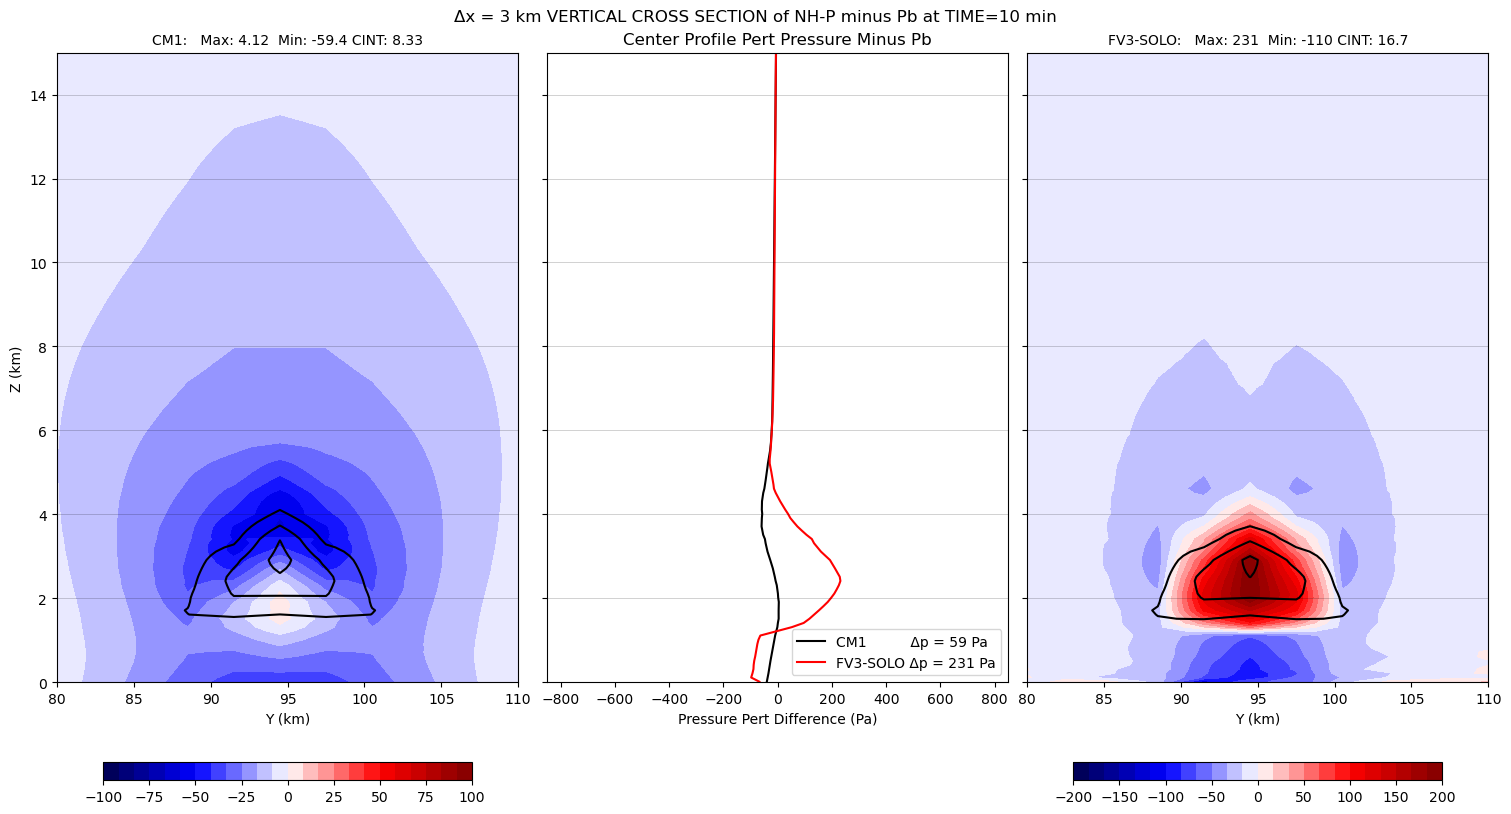

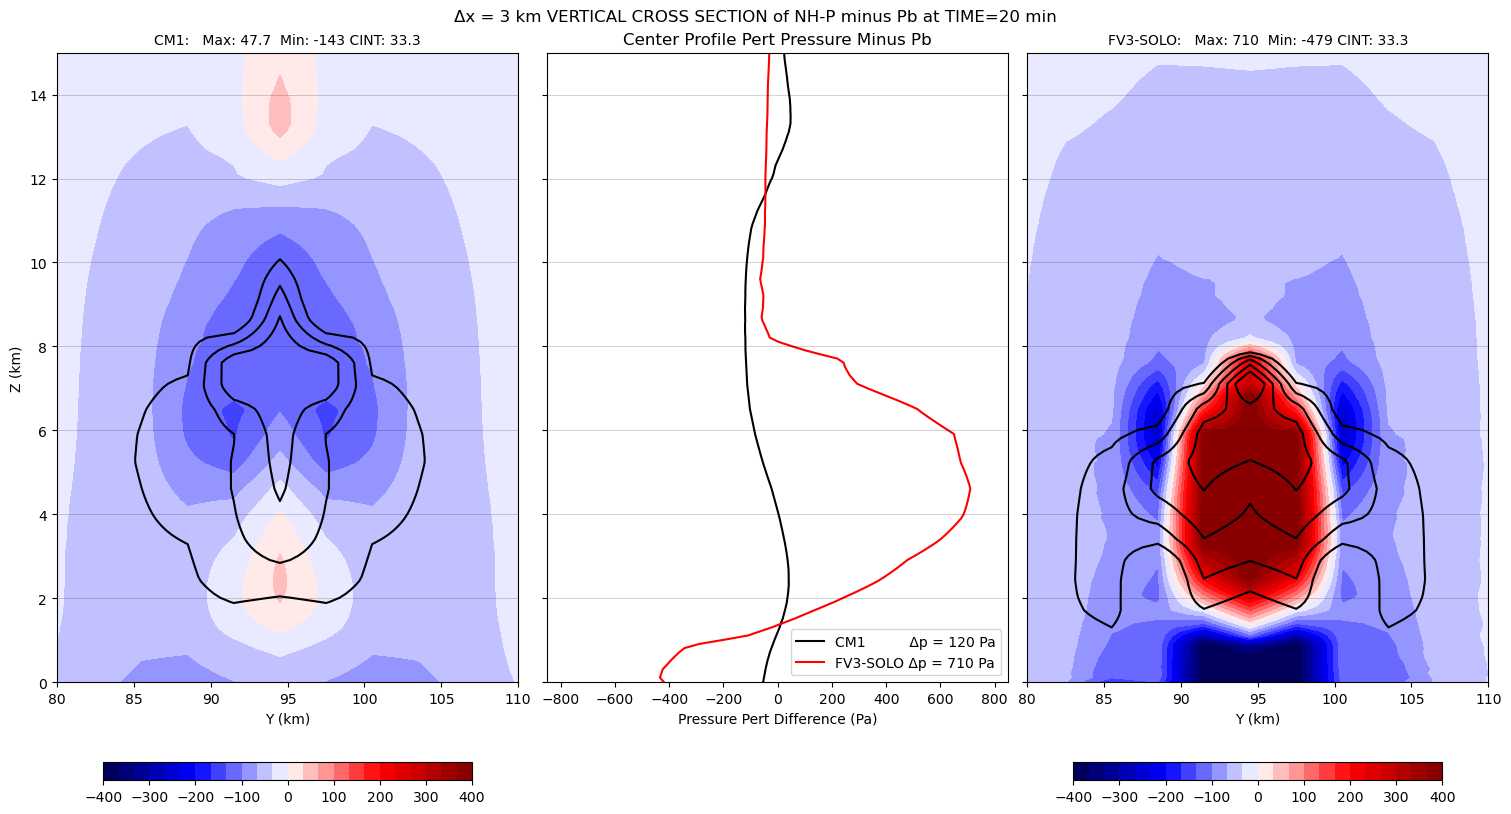

In [182]:

solo = models['solo']
cm1  = models['cm1']

time1 = solo['min'][:]
time2 = cm1['min'][:]
xc    = cm1['xc']/1000.
yc    = cm1['yc']/1000.

nx2 = (xc.shape[0]//2) - 1
ny2 = (yc.shape[0]//2) - 1

dp_unicode = "\u0394p"
linestyles = [':','--','solid'] 

for tlevel in [10, 20]:

    match tlevel:
        case 1:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 5:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*1 for x in pclevs]
        case 10:
             pclevs  = list(np.linspace(-100,100,25))
             pclevs2 = [x*2 for x in pclevs]
        case 15:
            pclevs  = list(np.linspace(-200,200,25))
            pclevs2 = [x*2 for x in pclevs]
        case 20:
            pclevs  = list(np.linspace(-400,400,25))
            pclevs2 = [x*1 for x in pclevs]
        case 30:
            pclevs  = list(np.linspace(-100,100,25))
            pclevs2 = [x*5 for x in pclevs]

    ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,8))

    pdiff_cm1  =  cm1['pert_p'][tlevel,  :,nx2,ny2] - cm1['pb'][tlevel, :,nx2,ny2]
    pdiff_solo = solo['pert_p2'][tlevel-1,:,nx2,ny2] - solo['pb'][tlevel-1,:,nx2,ny2]

    axes[1].plot(pdiff_cm1,  zlevels/1000., color='k', linestyle=linestyles[2], label=f'CM1          {dp_unicode} = {int(np.abs(pdiff_cm1).max())} Pa')
    axes[1].plot(pdiff_solo, zlevels/1000., color='r', linestyle=linestyles[2], label=f'FV3-SOLO {dp_unicode} = {int(np.abs(pdiff_solo).max())} Pa')
    axes[1].legend()
    axes[1].set_title(f"Center Profile Pert Pressure Minus Pb")
    axes[1].set_xlim(-850,850)

    fields = []
    fields.append(container( cm1['pert_p'][tlevel,  :,:,ny2] - cm1['pb'][tlevel,  :,:,ny2], yc, zlevels/1000., cint=pclevs, cmap=plt.cm.seismic))
    # fields.append(container( cm1_w0['pert_p'][tlevel,  :,:,ny2], yc, zlevels/1000.,   cint=pclevs, cmap=plt.cm.seismic))
    fields.append(container( solo['pert_p2'][tlevel-1,:,:,ny2] - solo['pb'][tlevel-1,:,:,ny2], yc, zlevels/1000., cint=pclevs2, cmap=plt.cm.seismic)) 

    plot_contour_row(fields, plot_type=2, ptitle=['CM1', 'FV3-SOLO'], suptitle=f"\u0394x = 3 km VERTICAL CROSS SECTION of NH-P minus Pb at TIME={tlevel} min", 
                     xlabel='X (km)', ylabel='Z (km)', xlim=[80.,112.], ax_in=[axes[0],axes[2]]);

    axes[0].set_xlim(80.,110.)
    axes[2].set_xlim(80.,110.)
    axes[0].set_xlabel('Y (km)')
    axes[2].set_xlabel('Y (km)')
    axes[1].set_xlabel('Pressure Pert Difference (Pa)')
    axes[0].set_ylim(0.,15.)
    axes[2].set_ylim(0.,15.)

    bclevs  = list(np.linspace(0.025,0.225,5))
    axes[0].contour(yc, zlevels/1000., cm1['buoy'][tlevel,  :,:,ny2], levels=bclevs,  colors=['k',], linewidth=[0.5,] )
    axes[2].contour(yc, zlevels/1000., solo['buoy'][tlevel-1,:,:,ny2], levels=bclevs, colors=['k',], linewidth=[0.5,] )

    #     # max p label
    # ckmax, _, _ = find_max_ijk(cm1['pert_p'][tlevel])
    # skmax, _, _ = find_max_ijk(solo[pfield][tlevel-1])
    # axes[0].axhline(y = zlevels[ckmax]/1000., xmin=0.5, xmax=1.0, color = 'k', alpha=0.5, linestyle=linestyles[0], linewidth=3.0 )
    # axes[2].axhline(y = zlevels[skmax]/1000., xmin=0.0, xmax=0.5, color = 'k', alpha=0.5, linestyle=linestyles[0], linewidth=3.0 )
    # trans = transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
    # axes[0].text(0.925, 1 + zlevels[ckmax]/1000., "Pmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='right')
    # trans = transforms.blended_transform_factory(axes[2].transAxes, axes[2].transData)
    # axes[2].text(0.075, 1 + zlevels[skmax]/1000., "Pmax", transform=trans, fontsize=12, color='k', verticalalignment='center', horizontalalignment='left')

    # # max w label
    # ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    # skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])
    # axes[0].axhline(y = zlevels[ckmax]/1000., xmin=0., xmax=0.5, color = 'k', alpha=0.5, linestyle=linestyles[2], linewidth=3.0 )
    # axes[2].axhline(y = zlevels[skmax]/1000., xmin=0.5, xmax=1.0, color = 'k', alpha=0.5, linestyle=linestyles[2], linewidth=3.0 )
    # trans = transforms.blended_transform_factory(axes[0].transAxes, axes[0].transData)
    # axes[0].text(0.075, 1 + zlevels[ckmax]/1000., "Wmax", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='left')
    # trans = transforms.blended_transform_factory(axes[2].transAxes, axes[2].transData)
    # axes[2].text(0.925, 1 + zlevels[skmax]/1000., "Wmax", transform=trans, fontsize=12, color='k', verticalalignment='center', horizontalalignment='right')
    
    # other lines of interest
    for hgt in [2., 4., 6.0, 8.0, 10., 12., 14.0]:
        axes[0].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
        axes[1].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )
        axes[2].axhline(y = hgt, color = 'k', alpha=0.25, linestyle=linestyles[2], linewidth=0.5 )

    axes[0].set_ylabel('Z (km)', fontsize=10);
    #label_panels(axes, ['(a)', '(b)', '(c)'], fontsize=18)

    plt.savefig("../Figures/Figure15_XZ_PertP_Buoy_3km_DIFF_TIME_%2.2d_min.pdf" % tlevel)

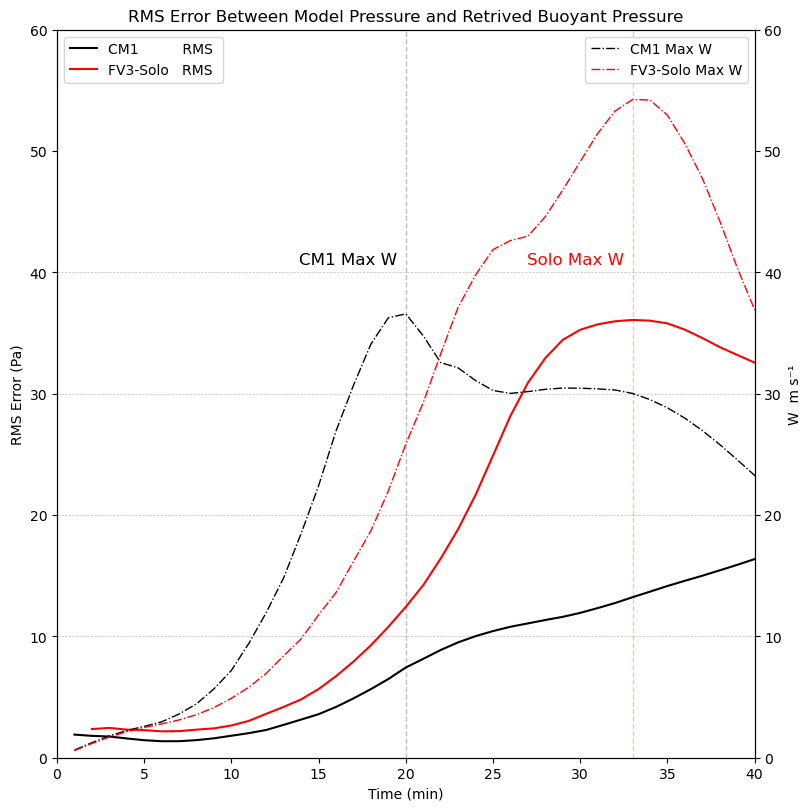

In [135]:
solo = models['solo']
cm1  = models['cm1']

cm1_time  = cm1['min'][:]
solo_time = solo['min'][:]

pdiff_cm1  =  (cm1['pert_p'] - cm1['pb'])**2
pdiff_solo = (solo['pert_p3'] - solo['pb'])**2

cm1_rms = np.sqrt( pdiff_cm1.sum(axis=(1,2,3)) * pdiff_cm1.shape[0] / pdiff_cm1.size )
solo_rms = np.sqrt( pdiff_solo.sum(axis=(1,2,3)) * pdiff_solo.shape[0] / pdiff_solo.size )

cm1_rms = np.sqrt( pdiff_cm1.sum(axis=(1,2,3)) * pdiff_cm1.shape[0] / pdiff_cm1.size )

fig, axes = plt.subplots(1, 1, sharey=True, constrained_layout=True, figsize=(8,8))


axes.plot(cm1_time[1:], cm1_rms[1:],  color='k', linestyle=linestyles[2], label=f'CM1          RMS ')
axes.plot(solo_time[1:], solo_rms[1:],  color='r', linestyle=linestyles[2], label=f'FV3-Solo   RMS ')
axes.legend()
axes.set_title(f"Center Profile Pert Pressure Minus Pb")
axes.set_ylim(0.,60.)
axes.set_xlim(0.,40.)

axes.set_xlabel('Time (min)')
axes.set_ylabel('RMS Error (Pa)')
axes.set_title('RMS Error Between Model Pressure and Retrived Buoyant Pressure')

axes.axvline(x = 20., color = 'k', alpha=0.25, linestyle='--', linewidth=1)
axes.axvline(x = 33., color = 'r', alpha=0.25, linestyle='--', linewidth=1)
trans = transforms.blended_transform_factory(axes.transData, axes.transData)
axes.text(19.5, 41, "CM1 Max W", transform=trans, fontsize=12,  color='k', verticalalignment='center', horizontalalignment='right')
axes.text(32.5, 41, "Solo Max W", transform=trans, fontsize=12,  color='r', verticalalignment='center', horizontalalignment='right')

for hgt in [10,20,30,40,60]:
    axes.axhline(y = hgt, color = 'k', alpha=0.25, linestyle='--', linewidth=0.5 )

# Create the second Axes object, sharing the x-axis
ax2 = axes.twinx()

ax2.plot(cm1_time[1:], cm1['w'][1:].max(axis=(1,2,3)), label=f"CM1 Max W", linestyle='-.', color='k',linewidth=1)
ax2.plot(solo_time, solo['w'].max(axis=(1,2,3)), label=f"FV3-Solo Max W", linestyle='-.', color='r', linewidth=1)
ax2.set_ylabel('W  m s\u207B\u00B9')
axes.set_ylim(0.,60.)
ax2.set_ylim(0.,60.)

axes.legend()
ax2.legend()

plt.savefig("../Figures/Figure16_TimeSeries_RMS_PP_Pb.pdf")

In [ ]:
####### 

In [22]:
from ../spectra import py_spectra

cm1_var  = np.zeros((nt,nx//2))
solo_var = np.zeros((nt,nx//2))

nt     = 21
nstart = 10

_sep1 = ' ' * 10

for n, tlevel in enumerate(nstart+np.arange(nt)):

    flat_max_index = np.argmax( cm1['w'][tlevel,  :,:, nx2] )
    k_index, y_index = np.unravel_index(flat_max_index, cm1['w'][tlevel, :, :, nx2].shape)
    # print(f"The CM1 maximum value is at k: {k_index}, y: {y_index}")
    cm1_max_row = cm1['w'][tlevel, k_index , :, :]

    flat_max_index = np.argmax( solo['w'][tlevel-1,  :, :, nx2] )
    k_index, y_index = np.unravel_index(flat_max_index, cm1['w'][tlevel, :, :, ny2].shape)
    # print(f"The SOLO maximum value is at k: {k_index}, y: {y_index}")
    solo_max_row = solo['w'][tlevel-1, k_index , :, :]

    kvals, cm1_var[n,:],  wavenumber = py_spectra.get_spectra2D_DCT(cm1_max_row, dx=1., dy=1., varray = None, sep=_sep1)
    kvals, solo_var[n,:], wavenumber = py_spectra.get_spectra2D_DCT(solo_max_row, dx=1., dy=1., varray = None, sep=_sep1)

#---------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1,1, constrained_layout=True,figsize=(8,8))

for n in [0,2]:

    m = n*5

    ax.loglog(wavenumber[1:-1], cm1_var[m:m+6].mean(axis=0)[1:-1], color='k', linestyle=linestyles[n], label=f'CM1 averaged over {m+10}-{m+15} min')
    ax.loglog(wavenumber[1:-1], solo_var[m:m+6].mean(axis=0)[1:-1], color='r', linestyle=linestyles[n], label=f'FV3-SOLO averaged over {m+10}-{m+15} min')

ax.legend(fontsize=10, loc='lower left')

# Label x-axis

xlabels    = [f'{x:2d}\u0394x' for x in [2, 4, 6, 8, 10, 15]]
label_xlim = [2.0/x for x in [2, 4, 6, 8, 10, 15]]
    
ax.set_xticks(label_xlim, xlabels)

for n, w in enumerate([2.0, 4.0, 6.0, 8.0, 10., 15.]):
    ax.axvline(x = 2.0/w, color = 'grey', alpha=0.5)  

ax.set_ylabel(r"Energy Density (m$^3$ s$^{-2}$)", fontsize=12);
ax.set_xlabel(r"Wavelength", fontsize=12);
ax.set_title('Vertical KE for Bubble');

plt.savefig("./Figures/Vertical_KE_Spectra_3km.pdf")

SyntaxError: invalid syntax (2819561403.py, line 1)

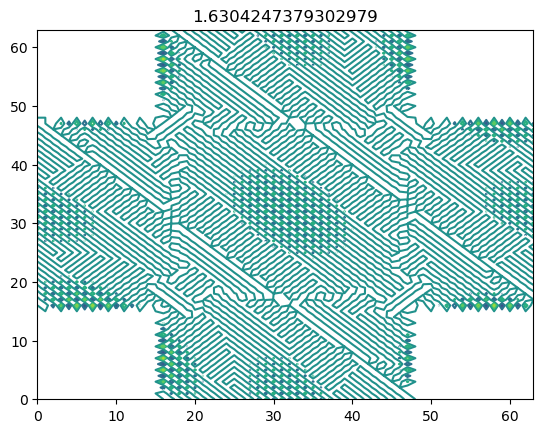

Text(0.5, 1.0, '1.6440587043762207')

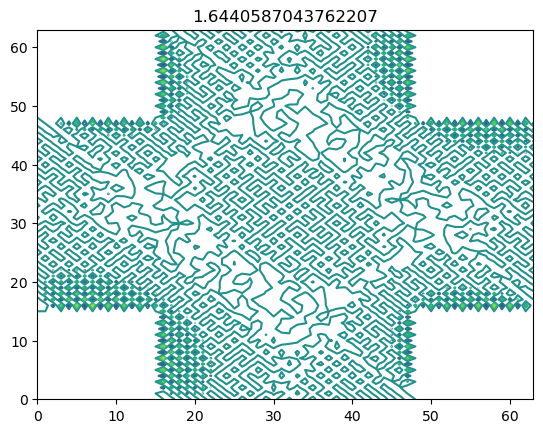

In [735]:
# FFT mositure fluxes
from scipy import fftpack

def compute_2D_spectrum(array, keep_fraction=0.5):

    im1  = fftpack.fft2(array)
    
    r, c = im1.shape

    if keep_fraction > 0.5:

        keep = 1.0 - keep_fraction

    else:

        keep = keep_fraction

    im2 = im1.copy()
    
    im2[int(r*keep):int(r*(1-keep))]   = 0.0
    im2[:,int(c*keep):int(c*(1-keep))] = 0.0

    if keep_fraction > 0.5:

        im3 = np.where(np.abs(im2) > 0.0, 0.0, im1)

        return fftpack.ifft2(im3).real, im3

    else:

        return fftpack.ifft2(im2).real, im2


########################################################################

nt       = cm1['rw'].shape[0]
nz       = len(zlevels)
nx       = xc.shape[0]
ny       = yc.shape[0]
cm1_filt  = np.zeros((nt,nz,ny,nx))
solo_filt = np.zeros((nt-1,nz,ny,nx))
cm1_spec  = np.zeros((nt,nz,ny,nx))
solo_spec = np.zeros((nt-1,nz,ny,nx))


keep_fraction = 0.75

for tlevel in np.arange(nt):

    for k in np.arange(nz):

        cm1_filt[tlevel,k], cm1_spec[tlevel,k] = compute_2D_spectrum(cm1['rw'][tlevel, k , :, :], keep_fraction=keep_fraction)

        if tlevel < nt-1:

            solo_filt[tlevel,k], solo_spec[tlevel,k] = compute_2D_spectrum(solo['rw'][tlevel, k , :, :], keep_fraction=keep_fraction)


plt.contour(cm1_spec[10,10,:,:]);
plt.title(f"{np.abs(cm1_spec[10,10,:,:]).max()}")
plt.show()
plt.contour(solo_spec[9,10,:,:]);
plt.title(f"{np.abs(solo_spec[9,10,:,:]).max()}")

(60, 200) (60, 200)


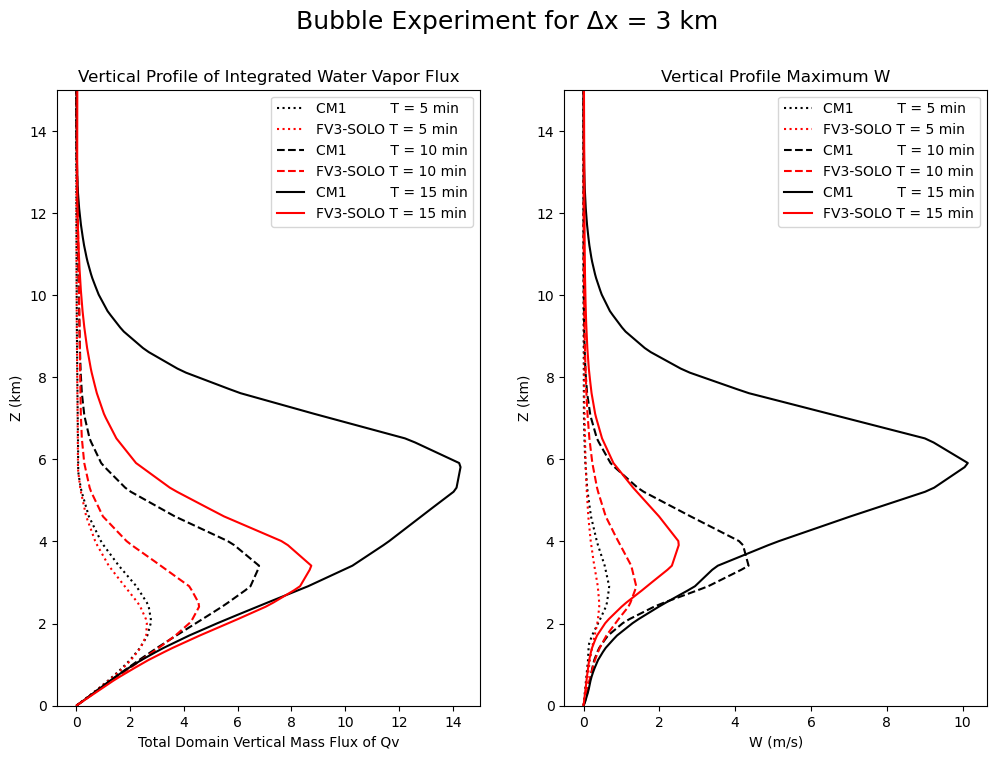

In [736]:
solo = models['solo']
cm1  = models['cm1']

time1 = solo['min'][:]
time2 = cm1['min'][:]
xc    = cm1['xc']
yc    = cm1['yc']

# cm1_rwq_profile = cm1['rw'][1:].sum(axis=(2,3)) 
# solo_rwq_profile = solo['rw'].sum(axis=(2,3))  

# cm1_filt_profile  = cm1_filt[1:].sum(axis=(2,3))
# solo_filt_profile = solo_filt.sum(axis=(2,3))

cm1_rwq_profile = cm1['rw'][1:].max(axis=(2,3)) 
solo_rwq_profile = solo['rw'].max(axis=(2,3))  

cm1_filt_profile  = cm1_filt[1:].max(axis=(2,3))
solo_filt_profile = solo_filt.max(axis=(2,3))


print(solo_rwq_profile.shape, solo_filt_profile.shape)

linestyles = [':', '--', 'solid', 'dashdot', ':'] 

fig, ax = plt.subplots(1,2, figsize=(12,8))

for n, t in enumerate([5, 10, 15]):

    ax[0].plot(cm1_rwq_profile[t], zlevels/1000., color='k', linestyle=linestyles[n],     label=f'CM1          T = {t} min')
    ax[0].plot(solo_rwq_profile[t], zlevels/1000., color='r', linestyle=linestyles[n],    label=f'FV3-SOLO T = {t} min')

    ax[1].plot(cm1_filt_profile[t], zlevels/1000., color='k', linestyle=linestyles[n],    label=f'CM1          T = {t} min')
    ax[1].plot(solo_filt_profile[t], zlevels/1000., color='r', linestyle=linestyles[n], label=f'FV3-SOLO T = {t} min')
    
    # solo_mass_flux = np.where(solo['rw'][t] > 2.5, solo['rw'][t], 0.0)
    # ax[1].plot(solo_mass_flux.sum(axis=(1,2)), zlevels/1000., color='r', linestyle=linestyles[n], label=f'FV3-SOLO T = {t} min')


ax[0].set_xlabel('Total Domain Vertical Mass Flux of Qv');
ax[0].set_ylabel('Z (km)');
ax[0].legend();
ax[0].set_title('Vertical Profile of Integrated Water Vapor Flux');

ax[1].set_xlabel('W (m/s)');
ax[1].set_ylabel('Z (km)');
ax[1].legend();
ax[1].set_title('Vertical Profile Maximum W');

ax[0].set_ylim(0,15.)
ax[1].set_ylim(0,15.)

plt.suptitle("Bubble Experiment for \u0394x = 3 km", fontsize=18)

plt.savefig("./Figures/Vertical_Water_Vapor_3km.pdf")


In [ ]:
from scipy import fftpack

nz       = len(zlevels)
nx       = xc.shape[0]
ny       = yc.shape[0]
cm1_var  = np.zeros((nt,nz,ny,nx))
solo_var = np.zeros((nt,nz,ny,nx))

nt     = 21
nstart = 10

linestyles = ['solid', '--', 'solid', 'dashdot', ':']

_sep1 = ' ' * 10

fig, ax = plt.subplots(1,2, figsize=(12,8))

keep_fraction = 0.5

for n, tlevel in enumerate(nstart+np.arange(nt)):

    for k in np.arange(nz):

        cm1_max_row = cm1['rwqv'][tlevel, k , :, :] * (3000.**2)
        im2         = fftpack.fft2(cm1_max_row)
        
        r, c = im2.shape

        im2[int(r*keep_fraction):int(r*(1-keep_fraction))] = 0.0
        im2[:,int(c*keep_fraction):int(c*(1-keep_fraction))] = 0.0
        cm1_var[n,k] = fftpack.ifft2(im2).real
        
        solo_max_row  = solo['rwqv'][tlevel-1, k , :, :] * (3000**2)
        im2           = fftpack.fft2(solo_max_row)
        r, c = im2.shape

        im2[int(r*keep_fraction):int(r*(1-keep_fraction))] = 0.0
        im2[:,int(c*keep_fraction):int(c*(1-keep_fraction))] = 0.0
        solo_var[n,k] = fftpack.ifft2(im2).real

        print(solo_var[n,k].max(), cm1_var[n,k].max())
        
# m = -1

# print(cm1_var[n,k].shape)

# for n in [10,20]:

#     m +=1

#     k = 20

#     ax[0].loglog(wavenumber[1:-1], cm1_var[n,k][1:-1],  color='k', linestyle=linestyles[m], label=f'CM1 averaged over {m+10}-{m+15} min')
#     ax[0].loglog(wavenumber[1:-1], solo_var[n,k][1:-1], color='r', linestyle=linestyles[m], label=f'FV3-SOLO averaged over {m+10}-{m+15} min')

# print(wavenumber[:-1])

ax[0].legend(fontsize=10, loc='lower left')

# Label x-axis

# xlabels    = [f'{x:2d}\u0394x' for x in [2, 4, 6, 8, 10, 15]]
# label_xlim = [2.0/x for x in [2, 4, 6, 8, 10, 15]]
    
# ax.set_xticks(label_xlim, xlabels)

# for n, w in enumerate([2.0, 4.0, 6.0, 8.0, 10., 15.]):
#     ax.axvline(x = 2.0/w, color = 'grey', alpha=0.5)  

# ax.set_ylabel(r"Energy Density (m$^3$ s$^{-2}$)", fontsize=12);
# ax.set_xlabel(r"Wavelength", fontsize=12);
# ax.set_title('Vertical KE for Bubble');



In [ ]:
solo = models['solo']
cm1  = models['cm1']

time1 = solo['min'][:]
time2 = cm1['min'][:]
xc    = cm1['xc']/1000.
yc    = cm1['yc']/1000.

nx2 = (xc.shape[0]//2) - 1
ny2 = (yc.shape[0]//2) - 1

for tlevel in [1, 5, 10, 15, 20, 25, 30]:

    match tlevel:
        case _:
            bclevs  = list(np.linspace(-0.2,0.2,25))
            bclevs2 = [x*1 for x in pclevs]

    ckmax, _, _ = find_max_ijk(cm1['w'][tlevel])
    skmax, _, _ = find_max_ijk(solo['w'][tlevel-1])

    fig, axes = plt.subplots(1, 3, sharey=True, constrained_layout=True, figsize=(15,7))

    # axes[1].plot(cm1['pert_p'][tlevel, :,nx2,ny2], zlevels/1000., color='k', linestyle=linestyles[0],     label=f'CM1            T = {tlevel} min')
    # axes[1].plot(solo['pert_p'][tlevel-1,:,nx2,ny2], zlevels/1000., color='r', linestyle=linestyles[1],   label=f'FV3-SOLO    T = {tlevel} min')
    # axes[1].legend()
    # axes[1].set_title(f"Center Profile  TIME={tlevel} min")
    # axes[1].set_xlim(-500,500)


    fields = []
    fields.append(container( cm1['buoy'][tlevel,  :,:,ny2], yc, zlevels/1000.,   cint=bclevs, cmap=plt.cm.seismic))
    fields.append(container( cm1_w0['buoy'][tlevel,  :,:,ny2], yc, zlevels/1000.,   cint=bclevs, cmap=plt.cm.seismic))
    fields.append(container(solo['buoy'][tlevel-1,:,:,ny2], yc, zlevels/1000.,   cint=bclevs, cmap=plt.cm.seismic)) 

    plot_contour_row(fields, ptitle=['CM1', 'CM1_WW0', 'FV3-SOLO'], suptitle=f"\u0394x = 3 km VERTICAL CROSS SECTION of Pert Pres at TIME={tlevel} min", 
                                 xlabel='X (km)', ylabel='Z (km)', xlim=[80.,112.], ax_in=[axes[0],axes[1],axes[2]]);
    
    # axes[0].axhline(y = zlevels[ckmax]/1000., color = 'k', alpha=0.5) 
    # axes[2].axhline(y = zlevels[skmax]/1000., color = 'r', alpha=0.5)  
    
    axes[0].set_ylabel('Z (km)', fontsize=10);
    axes[0].contour(yc, zlevels/1000., cm1['w'][tlevel,  :,:,ny2], levels=[5.0,],  colors=['k',], linewidth=[6.0,] )
    axes[1].contour(yc, zlevels/1000., cm1_w0['w'][tlevel,  :,:,ny2], levels=[5.0,],  colors=['k',], linewidth=[6.0,] )

    axes[2].contour(yc, zlevels/1000., solo['w'][tlevel-1,:,:,ny2], levels=[5.0,], colors=['k',], linewidth=[6.0,] )

    ckmax, _, _ = find_max_ijk(cm1['pert_p'][tlevel])
    skmax, _, _ = find_max_ijk(solo['pert_p'][tlevel-1])
    axes[0].axhline(y = zlevels[ckmax]/1000., color = 'k', alpha=0.5, linewidth=4.0 )
    axes[2].axhline(y = zlevels[skmax]/1000., color = 'r', alpha=0.5, linewidth=4.0 ) 


    label_panels(axes, ['(a)', '(b)', '(c)'], fontsize=18)

    plt.savefig("../Figures/Bubble_XZ_WW0_PertP_3km_TIME_%2.2d_min.pdf" % tlevel)

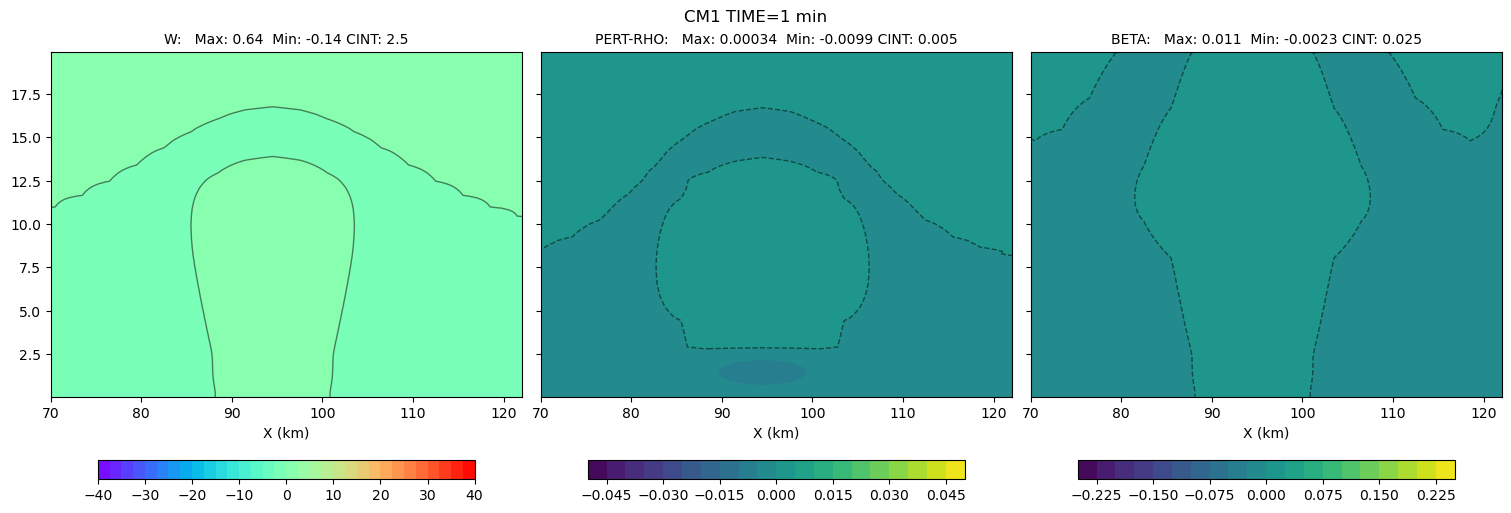

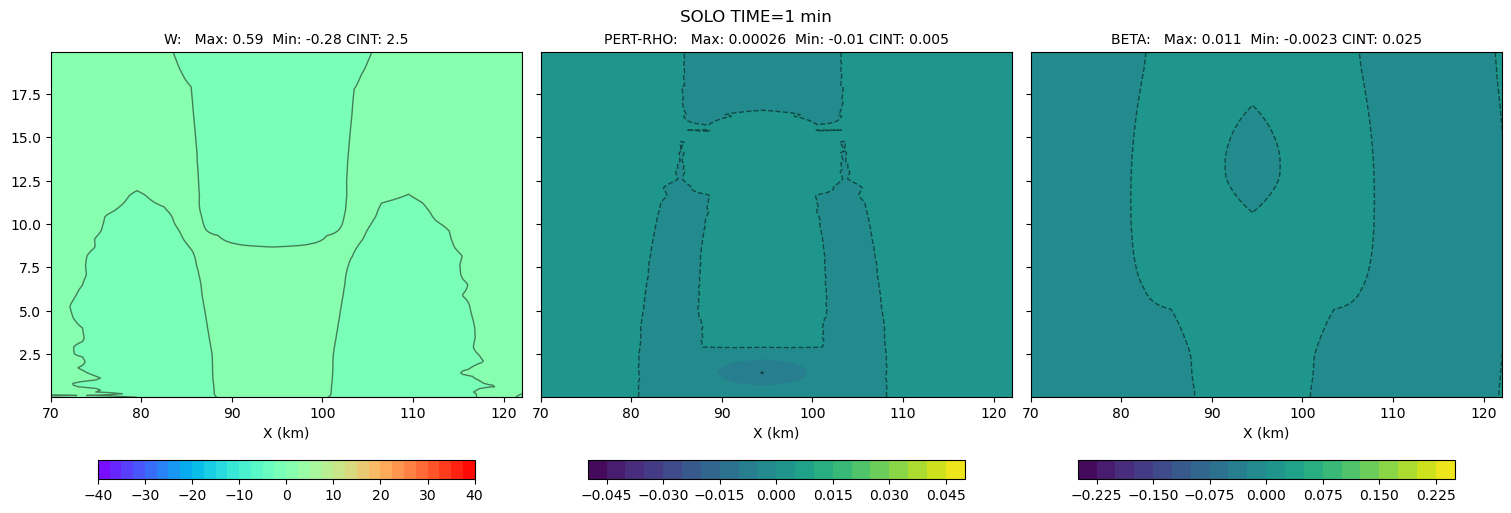

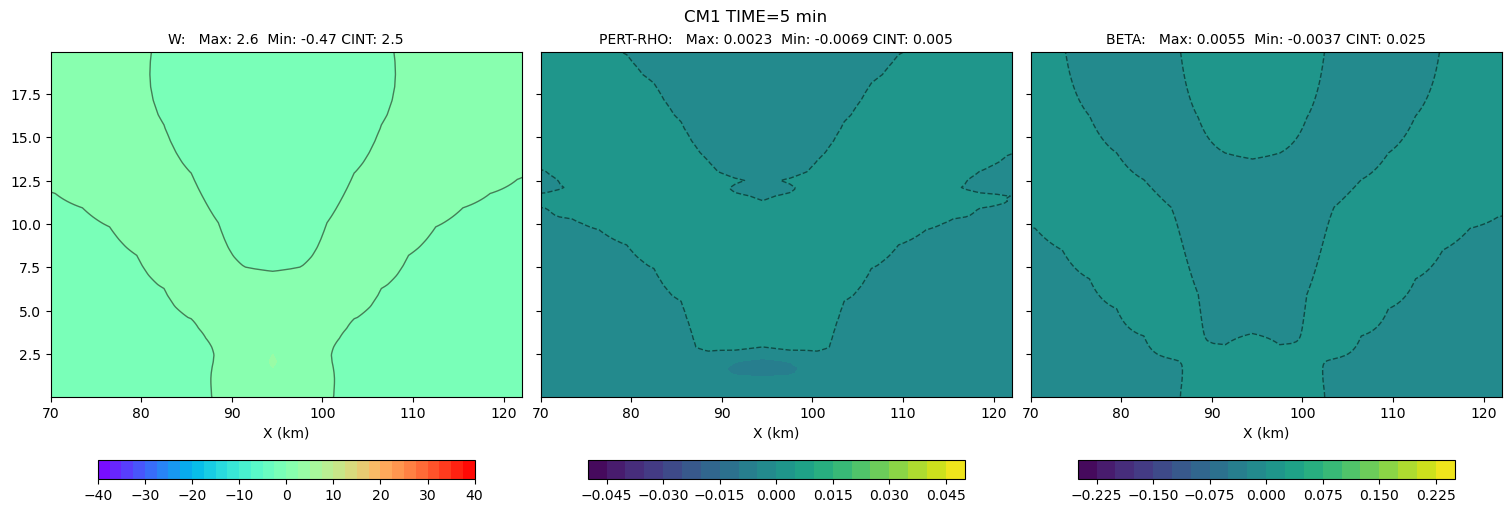

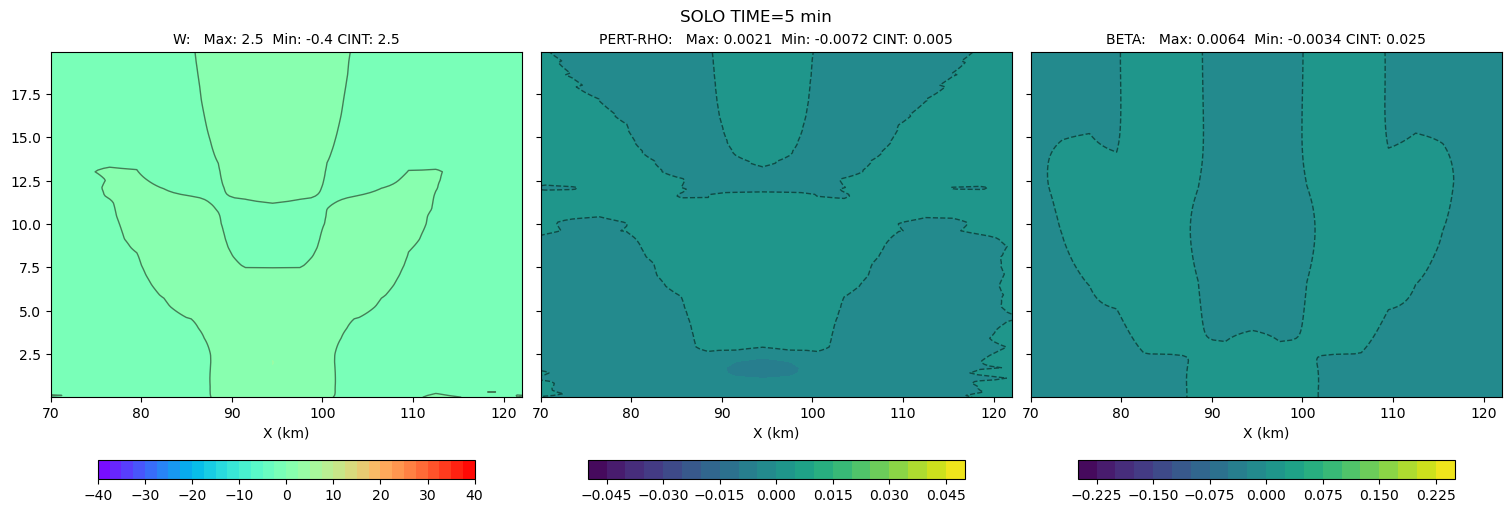

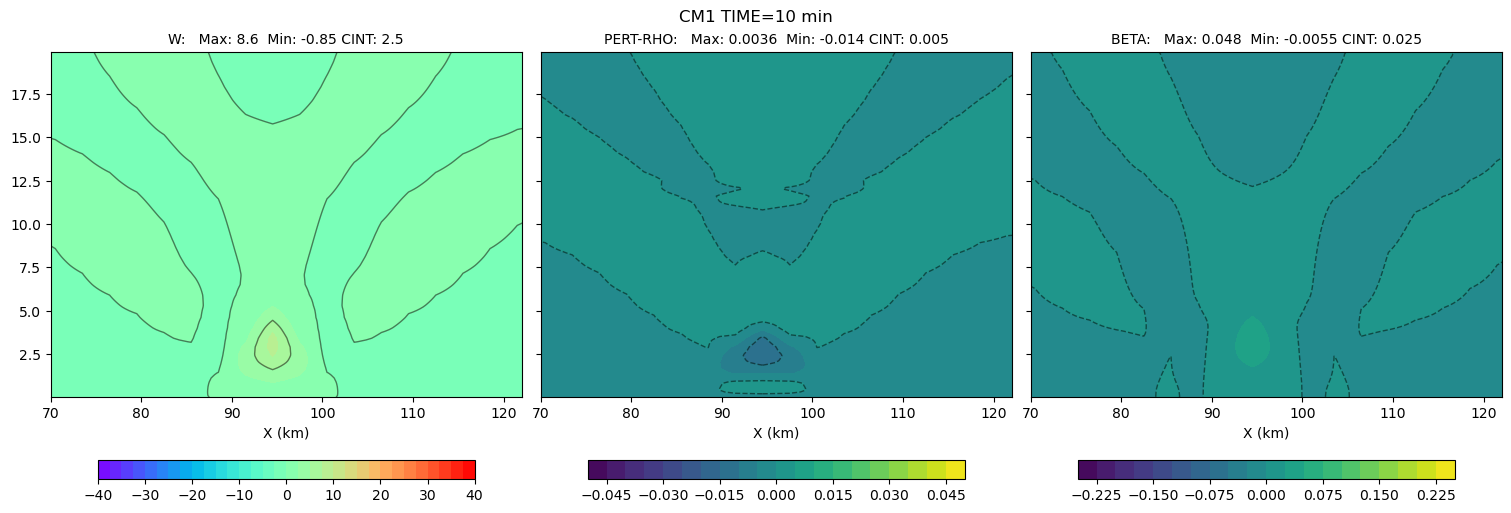

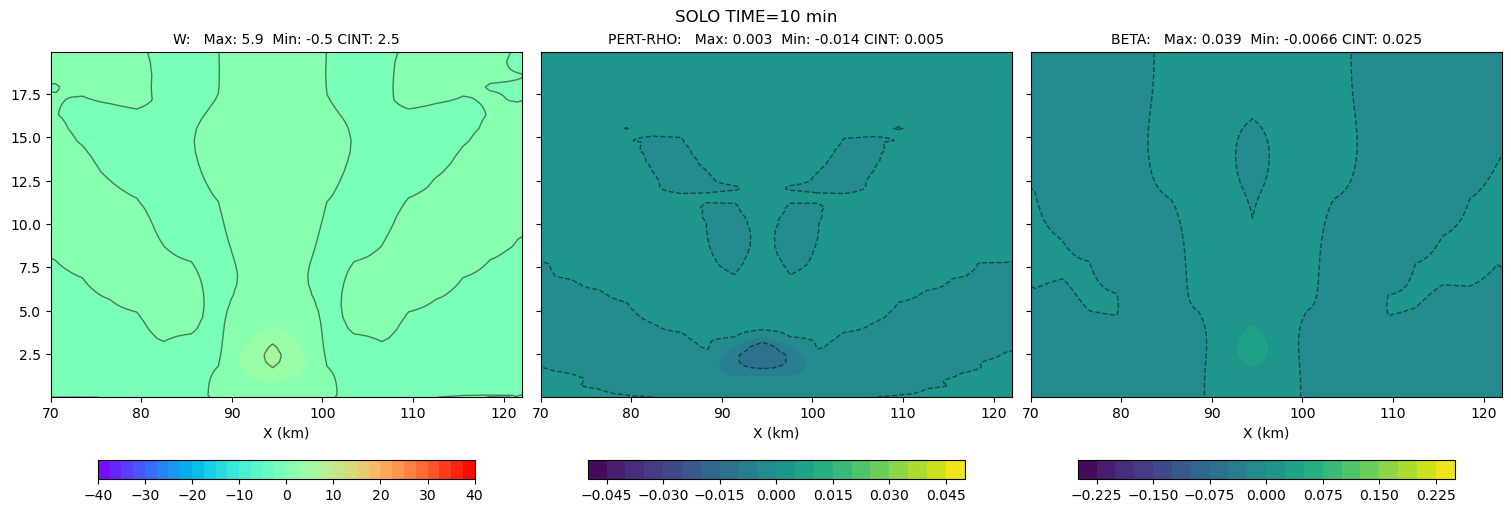

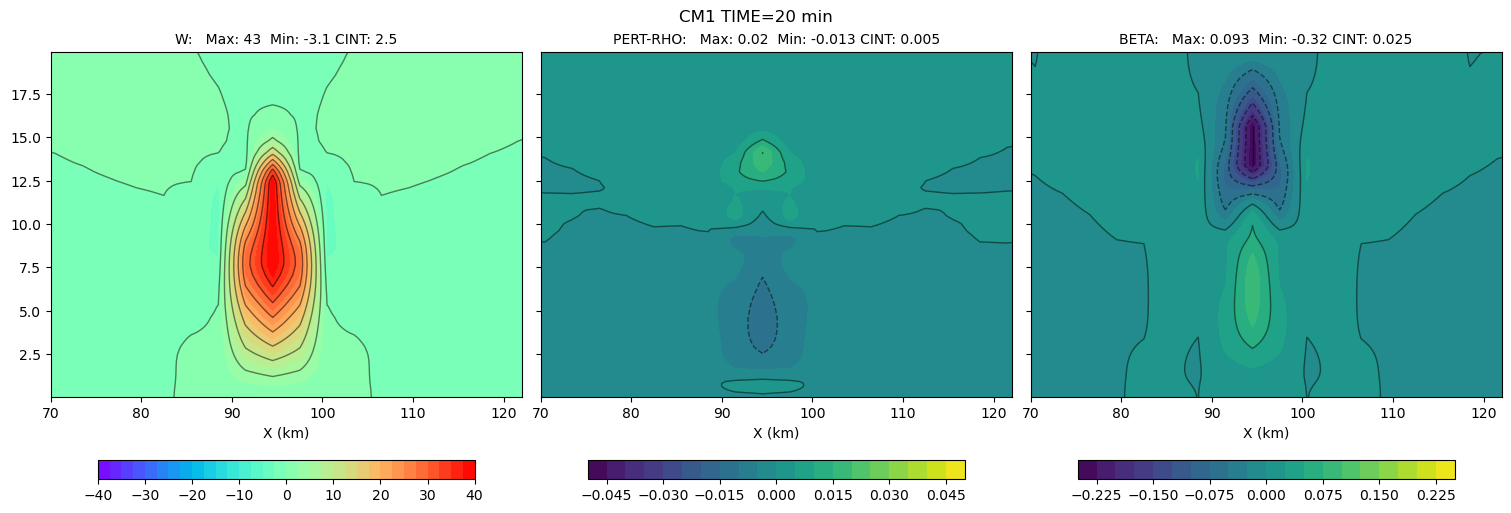

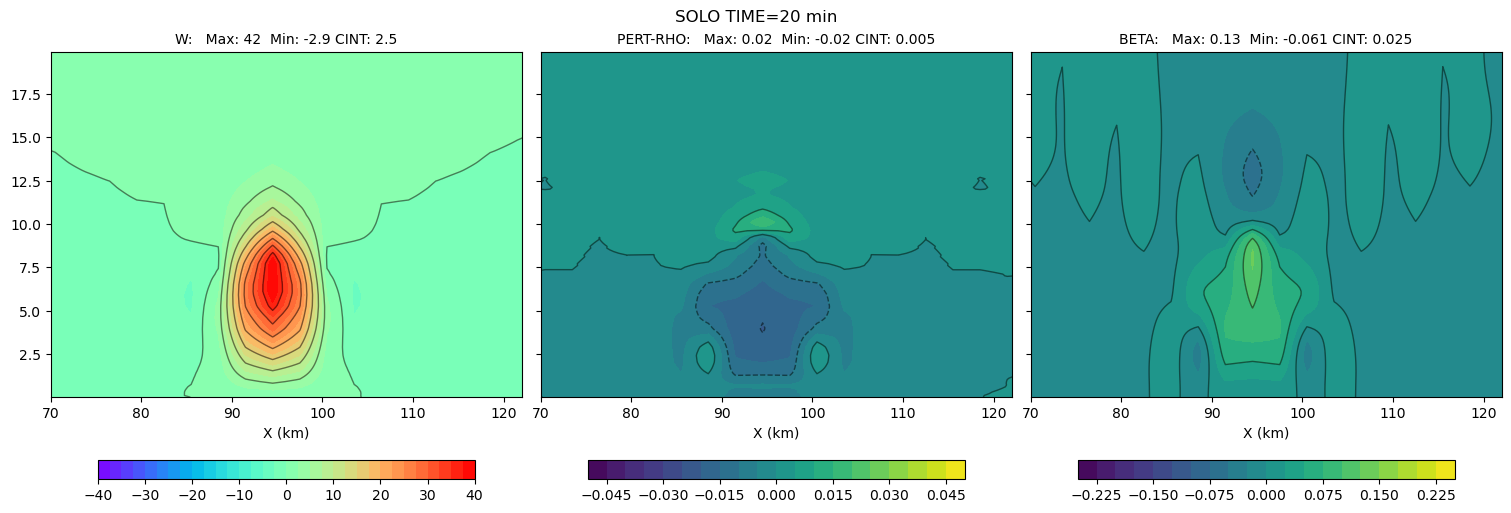

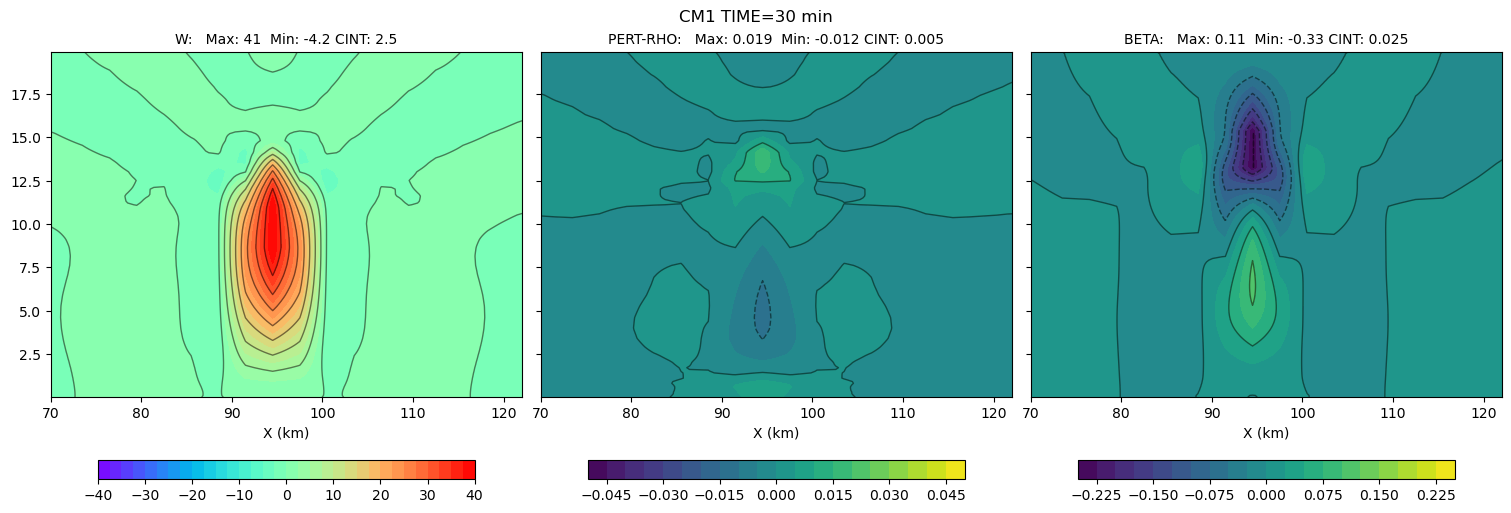

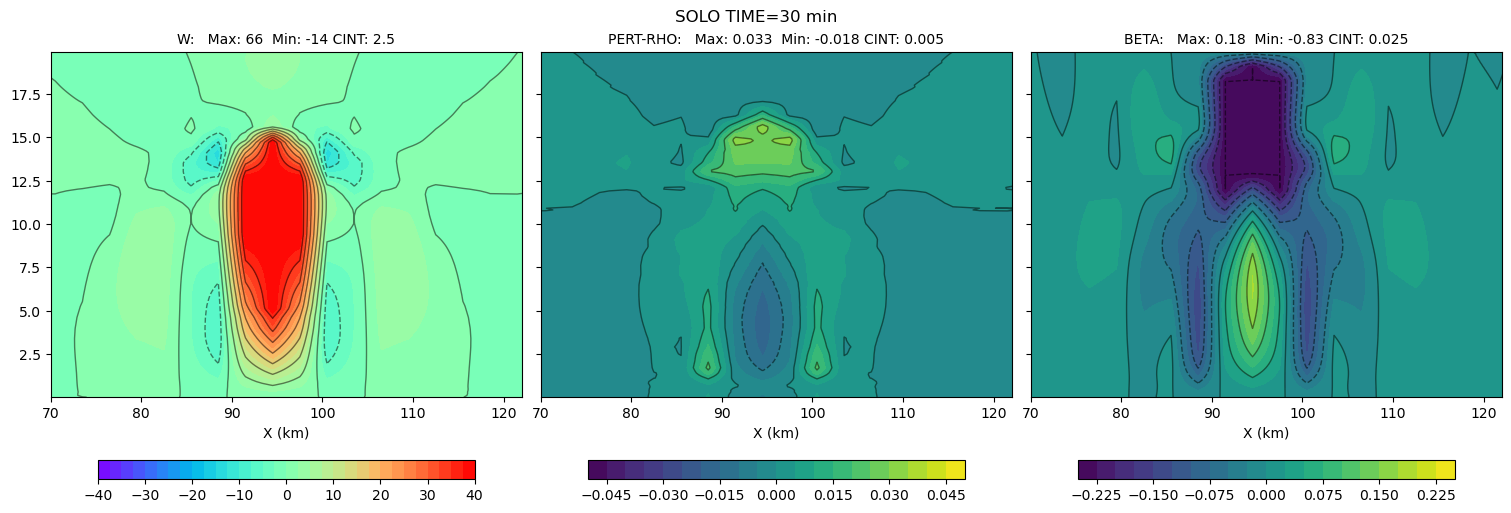

In [213]:
solo = models['solo']
cm1  = models['cm1']

time1 = solo['min'][:]
time2 = cm1['min'][:]
xc    = cm1['xc']/1000.
yc    = cm1['yc']/1000.

nx2 = (xc.shape[0]//2) - 1
ny2 = (yc.shape[0]//2) - 1

clevs = list(-3. + 0.25*np.arange(25))

time1 = solo['min'][:]
time2 = cm1['min'][:]
xc    = cm1['xc']/1000.
yc    = cm1['yc']/1000.

ny2 = (xc.shape[0]//2) - 1

wcint   = [-40.,40.,2.5]
rcint   = [-0.05, 0.05, 0.005]
bcint   = [-0.25, 0.25, 0.025]
c_focus = None

for tlevel in [1, 5, 10, 20, 30]:

    fields = []
    fields.append(container( cm1['w'][tlevel,  :,:,ny2],     yc, zlevels/1000.,    limit_fld=True, c_focus=c_focus,    cint=wcint, cmap=plt.cm.rainbow))
    fields.append(container( cm1['rho_p'][tlevel,  :,:,ny2], yc, zlevels/1000.,                  cint=rcint, cmap=plt.cm.viridis))
    fields.append(container( cm1['beta'][tlevel,  :,:,ny2],  yc, zlevels/1000.,                  cint=bcint, cmap=plt.cm.viridis))
    plot_contour_row(fields, ptitle=['W', 'PERT-RHO', 'BETA'], suptitle=f"CM1 TIME={tlevel} min", xlabel='X (km)', ylabel='Z (km)', xlim=[70.,122.], sharey=True);

    fields = []
    fields.append(container(solo['w'][tlevel-1,:,:,ny2], yc, zlevels/1000.,         limit_fld=True,  cint=wcint, cmap=plt.cm.rainbow))
    fields.append(container(solo['rho_p'][tlevel-1,:,:,ny2], yc, zlevels/1000.,                  cint=rcint, cmap=plt.cm.viridis))
    fields.append(container(solo['beta'][tlevel-1,:,:,ny2], yc, zlevels/1000.,                   cint=bcint, cmap=plt.cm.viridis)) 
    plot_contour_row(fields, ptitle=['W', 'PERT-RHO', 'BETA'], suptitle=f"SOLO TIME={tlevel} min", xlabel='X (km)', ylabel='Z (km)', xlim=[70.,122.],
                     sharey=True);

    # fields = []
    # fields.append(container(div['w'][tlevel-1,:,:,ny2], yc, zlevels/1000.,     cint=wcint, cmap=plt.cm.rainbow))
    # fields.append(container(div['rho_p'][tlevel-1,:,:,ny2], yc, zlevels/1000., cint=rcint, cmap=plt.cm.viridis))
    # fields.append(container(div['beta'][tlevel-1,:,:,ny2], yc, zlevels/1000.,  cint=bcint, cmap=plt.cm.viridis))
    
    # plot_contour_row(fields, ptitle=['W', 'PERT-RHO', 'BETA'], suptitle=f"S-DIV TIME={tlevel} min", xlabel='X (km)', ylabel='Z (km)', xlim=[70.,122.],
    #                  sharey=True);


#plt.savefig(f"XZ_3km.png")

    # klevel = 10
    
    # fields = []
    # fields.append(container( cm1['beta'][tlevel,   klevel, :, :], yc, xc))
    # fields.append(container(solo['beta'][tlevel-1, klevel, :, :], yc, xc))
    # plot_contour_row(fields, ptitle=['CM1', 'SOLO'], suptitle=f"BUBBLE TIME={tlevel} min", xlabel='X (km)', ylabel='Y (km)', cmap=plt.cm.rainbow, cint=0.01);

# plt.savefig(f"Initial_Condition_XY_K10_3km.png")

# fields = []
# fields.append(container(cm1['pert_th'][0,:,96:160,23]-solo['theta_IC'][:,96:160,23], xc[96:160], zlevels/1000.))
# plot_contour_row(fields, ptitle=['DIFF'], title='BUBBLE', xlabel='X (km)', ylabel='Z (km)',  cmap=plt.cm.rainbow, cint=0.001)


# fields = []
# fields.append(container(cm1['pert_th'][0,klevel,96:160,0:64]-solo['theta_IC'][klevel,96:160,0:64], xc[96:160], yc[0:64]))
# plot_contour_row(fields, ptitle=['DIFF'], title='BUBBLE', xlabel='X (km)', ylabel='Y (km)', cmap=plt.cm.rainbow, cint=0.001);

# print((cm1['pert_th'][0,klevel,96:160,0:64]-solo['theta_IC'][klevel,96:160,0:64]).min())